In [ ]:
# Exécuter seulement dans Google Colab
!pip install myqlm -q -q

# Introduction
Ce TP est basé sur le framework `MyQLM`, dont le code et la documentation sont disponibles sur cette [page GitHub](https://myqlm.github.io/). L'objectif de la séance est d'implémenter l'algorithme de Simon, qui retrouve une chaîne de bits cachée avec un nombre de requêtes exponentiellement plus faible que tout algorithme classique.

In [ ]:
# Lire cette cellule, puis l'exécuter sans modification.
import numpy as np
from qat.lang import QRoutine, H, X, CNOT, Program
from qat.qpus import get_default_qpu

qpu = get_default_qpu()

def display_result(circuit, nbshots=0, idx=None):
  '''
  Utilitary function to provide a nice display of the circuits.
  '''
  result = qpu.submit(circuit.to_job(nbshots=nbshots, qubits=idx)) # Objet de la classe Result
  if nbshots:
      tmp = {}
      for sample in result:
          state = sample.state
          if not state in tmp:
              tmp[state] = 0.
          tmp[sample.state] += sample.probability
      for state, proba in tmp.items():
          print(f"État {state}: probabilité {proba:.3f}")
  else:
      for sample in result:
          if sample.amplitude is None: # No amplitude when only a subset of qubits is measured
              print(f"État {sample.state}: probabilité {sample.probability:.3f}")
          else:
              print(f"État {sample.state}: probabilité {sample.probability:.3f}, amplitude {sample.amplitude:.3f}")

def get_samples(circuit, nbshots=20, idx=None):
    '''
    Run the circuit nbshots times and return the sorted list of distinct measured bitstrings.
    '''
    result = qpu.submit(circuit.to_job(nbshots=nbshots, qubits=idx))
    return sorted({sample.state.bitstring for sample in result})

# Description de l'algorithme

Soit $f:\{0,1\}^n \rightarrow \{0,1\}^n$ une fonction accessible uniquement via un oracle. On sait qu'il existe une chaîne secrète $s \in \{0,1\}^n$, $s \neq 0$, telle que
$$
f(x) = f(y) \iff y = x \oplus s,
$$
où $\oplus$ désigne le OU exclusif bit à bit.

**Problème de Simon :** retrouver $s$.

- **Classiquement**, il faut trouver deux entrées qui donnent la même valeur (une collision) : de l'ordre de $2^{n/2}$ requêtes à $f$ sont nécessaires.
- **Quantiquement**, l'[algorithme de Simon](https://fr.wikipedia.org/wiki/Algorithme_de_Simon) (1994) n'en demande que de l'ordre de $n$. C'est une séparation exponentielle, et l'algorithme a inspiré celui de Shor.

L'algorithme utilise deux registres de $n$ qubits, $x$ et $y$, et comporte 3 étapes :
1. **Superposition** : des portes $H$ sur le registre $x$ créent la superposition de toutes les entrées.
2. **Évaluation** : l'oracle $U_f \vert x \rangle \vert y \rangle = \vert x \rangle \vert y \oplus f(x) \rangle$ stocke $f(x)$ dans le registre $y$.
3. **Interférence** : des portes $H$ sur le registre $x$, puis mesure de $x$.

Le résultat $z$ de la mesure vérifie toujours $z \cdot s = 0 \mod 2$ : chaque exécution fournit une équation sur $s$. Après de l'ordre de $n$ exécutions, on dispose d'assez d'équations indépendantes pour déterminer $s$ par un post-traitement classique.

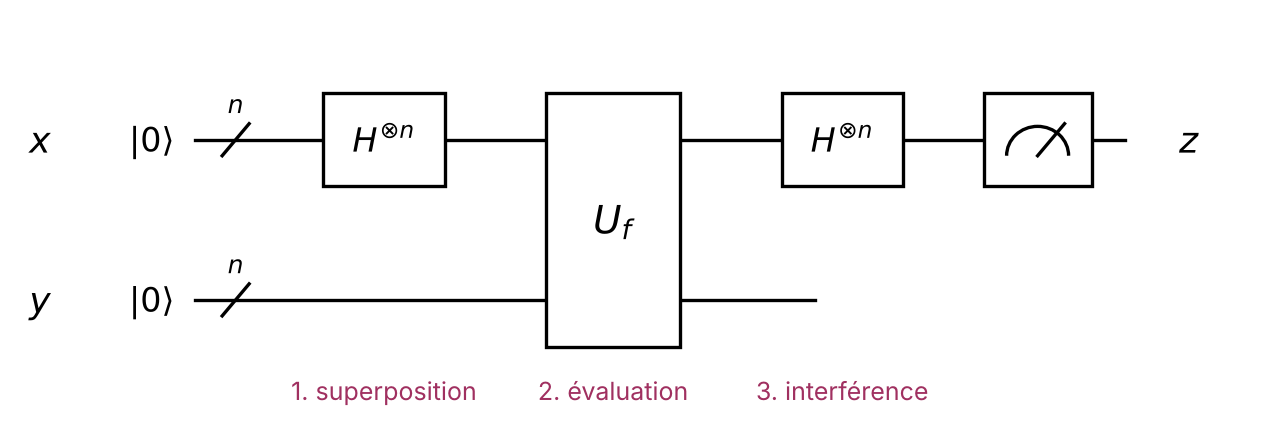


# Implémentation de l'algorithme

## Oracle de Simon

Pour tester l'algorithme, on construit un oracle pour un secret $s$ donné. Soit $p$ le premier indice tel que $s_p = 1$. On pose
$$
f(x) = x \oplus x_p \, s.
$$
Cette fonction vérifie bien $f(x) = f(y) \iff y = x \oplus s$ : $f(x)$ est le représentant de la paire $\{x, x \oplus s\}$ dont le bit $p$ vaut $0$.

**Question 1.** À la main, pour $n=3$ et $s=110$, calculer $f(x)$ pour tous les $x$ et vérifier que $f(x) = f(x \oplus s)$.

*RÉPONSE*

Le circuit de $U_f$ s'obtient en deux temps :
1. copier $x$ dans $y$ avec une porte CNOT entre $x_i$ et $y_i$, pour tout $i$ ;
2. pour chaque $j$ tel que $s_j = 1$, appliquer une porte CNOT entre $x_p$ et $y_j$, ce qui ajoute $x_p \, s$ à $y$.

**Question 2.** Implémenter la routine `simon_oracle` qui prend $s$ (liste de bits) en entrée et agit sur $2n$ qubits : le registre $x$, puis le registre $y$.

In [ ]:
def simon_oracle(s):
    n = len(s)

    # Routine creation
    rout = QRoutine()
    qubits = rout.new_wires(2 * n)

    # <<< COMPLETE HERE >>>

    return rout

**Question 3.** Pour $s = 110$, vérifier par simulation que $f(x) = f(x \oplus s)$ pour tous les $x$. Pour fixer $x$, on applique des portes $X$ sur le registre $x$ avant l'oracle : le registre $y$ contient alors $f(x)$.

In [ ]:
s = [1, 1, 0]
n = len(s)

# <<< COMPLETE HERE >>>

## Algorithme de Simon

Après les étapes 1 et 2, l'état du système est
$$
\frac{1}{\sqrt{2^n}} \sum_{x} \vert x \rangle \vert f(x) \rangle.
$$
Une porte $H$ sur chaque qubit du registre $x$ transforme $\vert x \rangle$ en $\frac{1}{\sqrt{2^n}} \sum_{z} (-1)^{x \cdot z} \vert z \rangle$, avec $x \cdot z = x_0 z_0 \oplus \dots \oplus x_{n-1} z_{n-1}$.

**Question 4.** À la main, en regroupant les termes $x$ et $x \oplus s$ qui ont la même valeur $f(x)$, montrer que l'amplitude de $\vert z \rangle \vert f(x) \rangle$ est proportionnelle à $1 + (-1)^{s \cdot z}$. En déduire que seuls les $z$ tels que $s \cdot z = 0 \mod 2$ peuvent être mesurés.

*RÉPONSE*

**Question 5.** Implémenter le programme quantique de l'algorithme de Simon, pour un oracle donné.

In [ ]:
def simon_circuit(n, oracle):
    # Program creation
    prog = Program()

    # Allocation of 2n qubits and n classical bits
    qubits = prog.qalloc(2 * n)
    bits = prog.calloc(n)

    # <<< COMPLETE HERE >>>

    # Final measurement of the x register
    prog.measure(qubits[:n], bits)

    return prog

**Question 6.** Tester l'algorithme pour $s = 110$ et vérifier si tous les $z$ mesurés vérifient $s \cdot z = 0 \mod 2$.

In [ ]:
s = [1, 1, 0]
n = len(s)

circuit = simon_circuit(n, simon_oracle(s)).to_circ()
display_result(circuit, nbshots=100, idx=list(range(n)))

## Post-traitement classique

Chaque mesure donne un $z$ tel que $s \cdot z = 0$. Pour $n$ petit, on retrouve $s$ par force brute : c'est l'unique chaîne non nulle orthogonale à tous les $z$ mesurés, si ceux-ci sont assez nombreux.

La fonction `get_samples` (fournie en début de notebook) renvoie la liste des $z$ distincts mesurés sur `nbshots` exécutions.

**Question 7.** Implémenter la fonction `find_secret` qui renvoie la liste des chaînes $s \neq 0$ vérifiant $s \cdot z = 0 \mod 2$ pour tous les $z$ de `samples`.

In [ ]:
def find_secret(samples, n):
    candidates = []

    # <<< COMPLETE HERE >>>

    return candidates

In [ ]:
samples = get_samples(circuit, nbshots=20, idx=list(range(n)))
print("Mesures :", samples)
print("Secret(s) candidat(s) :", find_secret(samples, n))

## Boîte noire

On fournit maintenant un oracle dont le secret $s$ est caché, sur $n=4$ bits. Il dépend de la graine `seed`, à remplacer par votre numéro d'étudiant.

In [ ]:
# Lire cette cellule, puis l'exécuter sans modification (sauf seed).
seed = 0  # Replace with your student number

def hidden_secret(n=4):
    rng = np.random.default_rng(seed)
    s = [0] * n
    while not any(s):
        s = rng.integers(0, 2, n).tolist()
    return s

def secret_oracle():
    '''
    Black-box oracle for Simon's problem with a hidden secret (n = 4).
    '''
    return simon_oracle(hidden_secret())

def check_secret(candidate):
    '''
    Check a candidate (string or list of bits) against the hidden secret.
    '''
    candidate = [int(b) for b in candidate]
    if candidate == hidden_secret():
        print("Correct")
    else:
        print("Incorrect")

**Question 8.** Retrouver le secret de `secret_oracle()` avec l'algorithme de Simon, puis le vérifier avec `check_secret`.

In [ ]:
n = 4

# <<< COMPLETE HERE >>>

## Pour aller plus loin

L'algorithme de Simon résout un problème de **période cachée** dans le groupe $(\mathbb{Z}/2\mathbb{Z})^n$ : $f(x) = f(x \oplus s)$. L'algorithme de Shor traite le même type de problème dans $\mathbb{Z}/N\mathbb{Z}$, en remplaçant les portes $H^{\otimes n}$ finales par la QFT.